<a href="https://colab.research.google.com/github/amritha-279/DS_SAT2_24CS017/blob/main/DS_SAT2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import files

uploaded = files.upload()


Saving customers.csv to customers (1).csv
Saving delivery.csv to delivery (1).csv
Saving orders.csv to orders (1).csv
Saving products.csv to products (1).csv
Saving returns.csv to returns (1).csv


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

orders = pd.read_csv("orders.csv")
products = pd.read_csv("products.csv")
customers = pd.read_csv("customers.csv")
delivery = pd.read_csv("delivery.csv")
returns = pd.read_csv("returns.csv")

print("All datasets loaded successfully!")
print("Orders:", orders.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Delivery:", delivery.shape)
print("Returns:", returns.shape)


All datasets loaded successfully!
Orders: (1201, 8)
Products: (80, 7)
Customers: (300, 4)
Delivery: (1200, 4)
Returns: (248, 5)


In [8]:

datasets = {
    "Orders": orders,
    "Products": products,
    "Customers": customers,
    "Delivery": delivery,
    "Returns": returns
}

for name, df in datasets.items():
    print("\n", name)
    print("Columns:", df.columns.tolist())
    display(df.head())



 Orders
Columns: ['order_id', 'order_date', 'product_id', 'customer_id', 'quantity', 'unit_price', 'discount', 'order_value']


,order_id,order_date,product_id,customer_id,quantity,unit_price,discount,order_value
0,O00001,2025-04-05,P075,C0051,1,263.02,0.25,197.26
1,O00002,2025-06-01,P034,C0052,2,447.14,0.25,670.71
2,O00003,2025-11-07,P008,C0144,1,306.91,0.20,245.53
3,O00004,2025-05-17,P077,C0132,2,152.45,0.10,274.41
4,O00005,2025-09-04,P074,C0039,1,42.64,0.20,34.11



 Products
Columns: ['product_id', 'product_name', 'category', 'brand', 'size', 'seller_id', 'unit_price']


,product_id,product_name,category,brand,size,seller_id,unit_price
0,P001,Footwear Item 001,Footwear,Everday,medium,S008,302.54
1,P002,Clothing Item 002,Clothing,BrightTech,Large,S011,434.16
2,P003,Electronic Item 003,Electronics,Peak,One Size,S003,18.13
3,P004,Accessorie Item 004,Accessories,StyleCo,S,S006,8.38
4,P005,Accessorie Item 005,Accessories,Nova,L,S010,266.18



 Customers
Columns: ['customer_id', 'customer_name', 'region', 'signup_date']


,customer_id,customer_name,region,signup_date
0,C0001,Customer 0001,West,2025-07-11
1,C0002,Customer 0002,South,2025-06-30
2,C0003,Customer 0003,South,2024-09-09
3,C0004,Customer 0004,East,2025-01-24
4,C0005,Customer 0005,North,2025-08-16



 Delivery
Columns: ['order_id', 'promised_date', 'delivered_date', 'courier']


,order_id,promised_date,delivered_date,courier
0,O00001,2025-04-10,2025-04-10,QuickRoute
1,O00002,2025-06-08,2025-06-08,National Express
2,O00003,2025-11-13,2025-11-16,FastShip
3,O00004,2025-05-21,2025-05-23,QuickRoute
4,O00005,2025-09-11,2025-09-11,National Express



 Returns
Columns: ['return_id', 'order_id', 'return_flag', 'return_reason', 'return_date']


,return_id,order_id,return_flag,return_reason,return_date
0,R00001,O00002,1,Changed mind,2025-06-22
1,R00002,O00011,1,Uncomfortable,2025-08-29
2,R00003,O00012,1,Changed mind,2025-02-02
3,R00004,O00015,1,NaN,2025-04-05
4,R00005,O00023,1,Damaged,2025-12-17


In [9]:

for name, df in datasets.items():
    print("\n", name)
    print(df.info())
    print("Missing values:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())



 Orders
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1201 entries, 0 to 1200
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     1201 non-null   object 
 1   order_date   1201 non-null   object 
 2   product_id   1201 non-null   object 
 3   customer_id  1201 non-null   object 
 4   quantity     1201 non-null   int64  
 5   unit_price   1201 non-null   float64
 6   discount     1201 non-null   float64
 7   order_value  1201 non-null   float64
dtypes: float64(3), int64(1), object(4)
memory usage: 75.2+ KB
None
Missing values:
order_id       0
order_date     0
product_id     0
customer_id    0
quantity       0
unit_price     0
discount       0
order_value    0
dtype: int64
Duplicate rows: 1

 Products
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id

In [10]:

for name, df in datasets.items():
    df.columns = (df.columns.str.strip()
                  .str.lower()
                  .str.replace(" ", "_"))

print("Column names standardized.")


Column names standardized.


In [11]:

for name, df in datasets.items():
    before = len(df)
    df.drop_duplicates(inplace=True)
    print(name, "- duplicate rows removed:", before - len(df))


Orders - duplicate rows removed: 1
Products - duplicate rows removed: 0
Customers - duplicate rows removed: 0
Delivery - duplicate rows removed: 0
Returns - duplicate rows removed: 0


In [12]:

for name, df in datasets.items():
    print("\n", name)
    print(df.isnull().sum()[df.isnull().sum() > 0])



 Orders
Series([], dtype: int64)

 Products
Series([], dtype: int64)

 Customers
Series([], dtype: int64)

 Delivery
Series([], dtype: int64)

 Returns
return_reason    2
dtype: int64


In [13]:

for name, df in datasets.items():
    print(name, ":", df.columns.tolist())


Orders : ['order_id', 'order_date', 'product_id', 'customer_id', 'quantity', 'unit_price', 'discount', 'order_value']
Products : ['product_id', 'product_name', 'category', 'brand', 'size', 'seller_id', 'unit_price']
Customers : ['customer_id', 'customer_name', 'region', 'signup_date']
Delivery : ['order_id', 'promised_date', 'delivered_date', 'courier']
Returns : ['return_id', 'order_id', 'return_flag', 'return_reason', 'return_date']


In [14]:

data = orders.merge(products, on="product_id", how="left")
data = data.merge(customers, on="customer_id", how="left")
data = data.merge(delivery, on="order_id", how="left")

# Use return records to identify returned orders
if "return_flag" in returns.columns:
    return_data = returns.drop_duplicates(subset=["order_id"])
    data = data.merge(return_data, on="order_id", how="left")
    data["return_flag"] = data["return_flag"].fillna(0)
else:
    returned_orders = returns[["order_id"]].drop_duplicates()
    returned_orders["return_flag"] = 1
    data = data.merge(returned_orders, on="order_id", how="left")
    data["return_flag"] = data["return_flag"].fillna(0)

print("Combined dataset:", data.shape)
display(data.head())


Combined dataset: (1200, 24)


,order_id,order_date,product_id,customer_id,quantity,unit_price_x,discount,order_value,product_name,category,...,customer_name,region,signup_date,promised_date,delivered_date,courier,return_id,return_flag,return_reason,return_date
0,O00001,2025-04-05,P075,C0051,1,263.02,0.25,197.26,Clothing Item 075,Clothing,...,Customer 0051,North,2024-01-23,2025-04-10,2025-04-10,QuickRoute,NaN,0.0,NaN,NaN
1,O00002,2025-06-01,P034,C0052,2,447.14,0.25,670.71,Footwear Item 034,Footwear,...,Customer 0052,Central,2025-07-18,2025-06-08,2025-06-08,National Express,R00001,1.0,Changed mind,2025-06-22
2,O00003,2025-11-07,P008,C0144,1,306.91,0.20,245.53,Electronic Item 008,Electronics,...,Customer 0144,North,2024-02-12,2025-11-13,2025-11-16,FastShip,NaN,0.0,NaN,NaN
3,O00004,2025-05-17,P077,C0132,2,152.45,0.10,274.41,Home Item 077,Home,...,Customer 0132,East,2024-11-25,2025-05-21,2025-05-23,QuickRoute,NaN,0.0,NaN,NaN
4,O00005,2025-09-04,P074,C0039,1,42.64,0.20,34.11,Beauty Item 074,Beauty,...,Customer 0039,Central,2025-05-25,2025-09-11,2025-09-11,National Express,NaN,0.0,NaN,NaN


In [15]:

print(data["return_flag"].value_counts())
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())


return_flag
0.0    952
1.0    248
Name: count, dtype: int64
Missing values: 2858
Duplicate rows: 0


In [16]:

if "return_reason" in data.columns:
    data["return_reason"] = data["return_reason"].fillna("Unknown")
elif "reason" in data.columns:
    data["reason"] = data["reason"].fillna("Unknown")

print("Missing return reasons handled where applicable.")


Missing return reasons handled where applicable.


In [17]:

display(data.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,1200,1200,O01184,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,1200,352,2025-10-20,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,1200,80,P055,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,1200,296,C0271,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,1200.0,NaN,NaN,NaN,1.504167,0.760788,1.0,1.0,1.0,2.0,4.0
unit_price_x,1200.0,NaN,NaN,NaN,253.453933,145.924305,8.38,141.5,261.0,402.68,497.32
discount,1200.0,NaN,NaN,NaN,0.120333,0.102569,0.0,0.05,0.1,0.2,1.75
order_value,1200.0,NaN,NaN,NaN,333.456833,279.016746,-272.59,141.575,266.175,426.275,1746.14
product_name,1200,80,Electronic Item 055,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1200,6,Clothing,326,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:

total_orders = len(data)
returned_orders = data["return_flag"].sum()
return_rate = returned_orders / total_orders * 100

print("Total records:", total_orders)
print("Returned records:", int(returned_orders))
print("Return rate:", round(return_rate, 2), "%")


Total records: 1200
Returned records: 248
Return rate: 20.67 %


category
Footwear       30.769231
Clothing       26.380368
Electronics    16.358025
Home           13.425926
Beauty         11.267606
Accessories     9.523810
Name: return_flag, dtype: float64


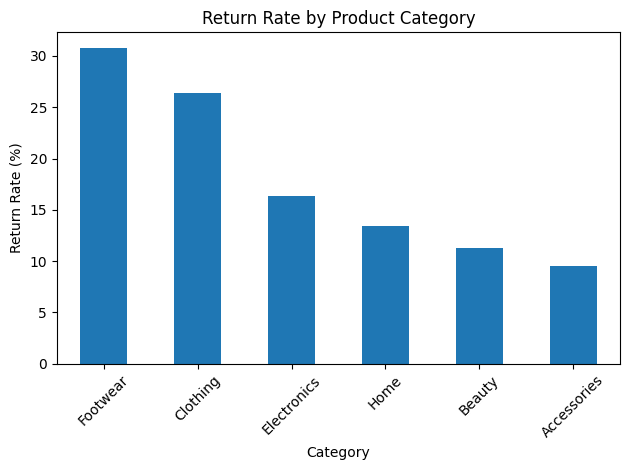

In [19]:

if "category" in data.columns:
    category_returns = data.groupby("category")["return_flag"].mean() * 100
    category_returns = category_returns.sort_values(ascending=False)

    print(category_returns)

    category_returns.plot(kind="bar")
    plt.title("Return Rate by Product Category")
    plt.xlabel("Category")
    plt.ylabel("Return Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


discount_group
Up to 10    20.666667
11-20             NaN
21-30             NaN
Above 30          NaN
Name: return_flag, dtype: float64


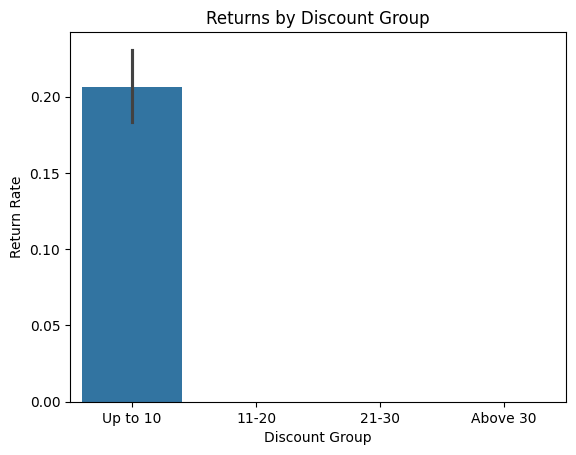

In [20]:

if "discount" in data.columns:
    data["discount_group"] = pd.cut(
        pd.to_numeric(data["discount"], errors="coerce"),
        bins=[-np.inf, 10, 20, 30, np.inf],
        labels=["Up to 10", "11-20", "21-30", "Above 30"]
    )

    print(data.groupby("discount_group", observed=False)["return_flag"].mean() * 100)

    sns.barplot(data=data, x="discount_group", y="return_flag")
    plt.title("Returns by Discount Group")
    plt.xlabel("Discount Group")
    plt.ylabel("Return Rate")
    plt.show()


late_delivery
0    17.812500
1    23.928571
Name: return_flag, dtype: float64


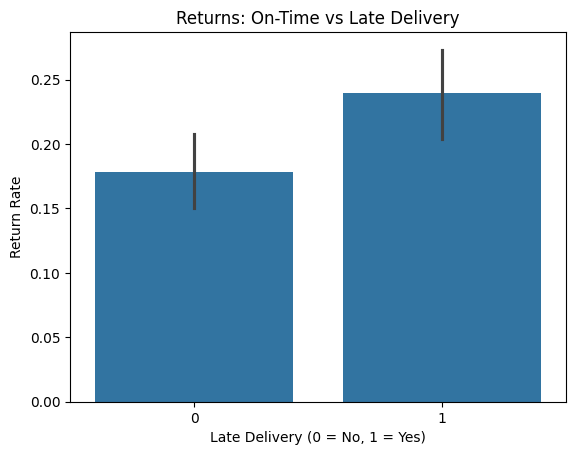

In [21]:

if "promised_date" in data.columns and "delivered_date" in data.columns:
    data["promised_date"] = pd.to_datetime(
        data["promised_date"], errors="coerce"
    )
    data["delivered_date"] = pd.to_datetime(
        data["delivered_date"], errors="coerce"
    )

    data["delivery_delay_days"] = (
        data["delivered_date"] - data["promised_date"]
    ).dt.days

    data["late_delivery"] = (
        data["delivery_delay_days"] > 0
    ).astype(int)

    print(data.groupby("late_delivery")["return_flag"].mean() * 100)

    sns.barplot(data=data, x="late_delivery", y="return_flag")
    plt.title("Returns: On-Time vs Late Delivery")
    plt.xlabel("Late Delivery (0 = No, 1 = Yes)")
    plt.ylabel("Return Rate")
    plt.show()


In [22]:

seller_col = None

if "seller" in data.columns:
    seller_col = "seller"
elif "seller_id" in data.columns:
    seller_col = "seller_id"

if seller_col:
    seller_returns = data.groupby(seller_col)["return_flag"].agg(
        ["sum", "count", "mean"]
    )

    seller_returns["return_rate"] = seller_returns["mean"] * 100
    seller_returns = seller_returns.sort_values(
        "return_rate", ascending=False
    )

    display(seller_returns.head(10))


,sum,count,mean,return_rate
seller_id,,,,
S003,37.0,129,0.286822,28.682171
S009,31.0,129,0.240310,24.031008
S004,33.0,141,0.234043,23.404255
S001,18.0,77,0.233766,23.376623
S007,24.0,104,0.230769,23.076923
S005,12.0,54,0.222222,22.222222
S013,20.0,97,0.206186,20.618557
S012,11.0,57,0.192982,19.298246
S015,9.0,48,0.187500,18.750000


customer_type
One-time    37.500000
Repeat      20.323129
Name: return_flag, dtype: float64


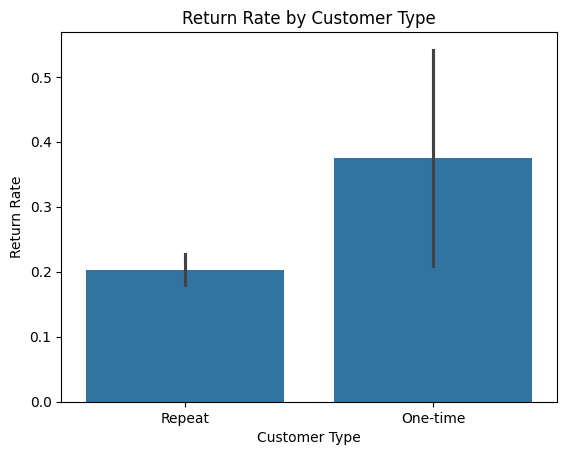

In [23]:

if "customer_id" in data.columns:
    customer_orders = data.groupby("customer_id")["order_id"].nunique()

    data["customer_type"] = data["customer_id"].map(
        lambda x: "Repeat" if customer_orders[x] > 1 else "One-time"
    )

    print(data.groupby("customer_type")["return_flag"].mean() * 100)

    sns.barplot(data=data, x="customer_type", y="return_flag")
    plt.title("Return Rate by Customer Type")
    plt.xlabel("Customer Type")
    plt.ylabel("Return Rate")
    plt.show()


In [24]:

if "quantity" in data.columns and "price" in data.columns:
    data["order_value"] = (
        pd.to_numeric(data["quantity"], errors="coerce") *
        pd.to_numeric(data["price"], errors="coerce")
    )

    print(data[["quantity", "price", "order_value"]].head())


In [25]:

if "order_date" in data.columns:
    data["order_date"] = pd.to_datetime(
        data["order_date"], errors="coerce"
    )
    data["order_month"] = data["order_date"].dt.month
    print(data[["order_date", "order_month"]].head())


  order_date  order_month
0 2025-04-05            4
1 2025-06-01            6
2 2025-11-07           11
3 2025-05-17            5
4 2025-09-04            9


In [26]:

categorical_cols = data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

encoded_data = pd.get_dummies(
    data,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Original shape:", data.shape)
print("Encoded shape:", encoded_data.shape)
display(encoded_data.head())


Original shape: (1200, 29)
Encoded shape: (1200, 2682)


,order_date,quantity,unit_price_x,discount,order_value,unit_price_y,promised_date,delivered_date,return_flag,delivery_delay_days,...,return_date_2026-01-12,return_date_2026-01-13,return_date_2026-01-15,return_date_2026-01-16,return_date_2026-01-18,return_date_2026-01-20,discount_group_11-20,discount_group_21-30,discount_group_Above 30,customer_type_Repeat
0,2025-04-05,1,263.02,0.25,197.26,263.02,2025-04-10,2025-04-10,0.0,0,...,0,0,0,0,0,0,0,0,0,1
1,2025-06-01,2,447.14,0.25,670.71,447.14,2025-06-08,2025-06-08,1.0,0,...,0,0,0,0,0,0,0,0,0,1
2,2025-11-07,1,306.91,0.20,245.53,306.91,2025-11-13,2025-11-16,0.0,3,...,0,0,0,0,0,0,0,0,0,1
3,2025-05-17,2,152.45,0.10,274.41,152.45,2025-05-21,2025-05-23,0.0,2,...,0,0,0,0,0,0,0,0,0,1
4,2025-09-04,1,42.64,0.20,34.11,42.64,2025-09-11,2025-09-11,0.0,0,...,0,0,0,0,0,0,0,0,0,1


In [27]:

numeric_data = data.select_dtypes(include="number")

if "return_flag" in numeric_data.columns:
    correlations = numeric_data.corr()["return_flag"].drop(
        "return_flag"
    )

    print(correlations.sort_values(ascending=False))


late_delivery          0.075355
delivery_delay_days    0.042825
discount               0.041298
unit_price_x          -0.001000
unit_price_y          -0.001000
order_month           -0.001115
order_value           -0.012979
quantity              -0.021740
Name: return_flag, dtype: float64


In [28]:

if "discount" in data.columns:
    print(data["discount"].describe())

    print("Negative discounts:",
          (data["discount"] < 0).sum())

    print("Discounts above 100:",
          (data["discount"] > 100).sum())


count    1200.000000
mean        0.120333
std         0.102569
min         0.000000
25%         0.050000
50%         0.100000
75%         0.200000
max         1.750000
Name: discount, dtype: float64
Negative discounts: 0
Discounts above 100: 0


In [29]:

if "size" in data.columns:
    data["size"] = data["size"].astype("string").str.strip().str.upper()

    data["size"] = data["size"].replace({
        "SMALL": "S",
        "MEDIUM": "M",
        "LARGE": "L",
        "EXTRA LARGE": "XL"
    })

    print(data["size"].value_counts())


size
ONE SIZE    611
S           101
L            87
M            83
XS           75
6            63
9            47
8            39
10           38
XL           36
SIZE 8       20
Name: count, dtype: Int64


In [30]:

if "promised_date" in data.columns and "delivered_date" in data.columns:
    invalid_dates = data[
        data["delivered_date"] < data["promised_date"]
    ]

    print("Delivery dates earlier than promised:",
          len(invalid_dates))


Delivery dates earlier than promised: 40


In [31]:

data.to_csv("cleaned_ecommerce_returns.csv", index=False)
encoded_data.to_csv("encoded_ecommerce_returns.csv", index=False)

print("Files saved successfully!")


Files saved successfully!


In [32]:

from google.colab import files

files.download("cleaned_ecommerce_returns.csv")
files.download("encoded_ecommerce_returns.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Drop non-predictive or target-leakage ID and date columns
exclude_cols = ["return_flag", "return_id", "return_reason", "return_date", "order_id", "customer_id", "product_id", "order_date", "promised_date", "delivered_date", "customer_name"]
features = [col for col in data.columns if col not in exclude_cols]

X = pd.get_dummies(data[features], drop_first=True)
y = data["return_flag"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")

Accuracy: 0.7958
F1-score: 0.0755
